# 01 – Data search: Sentinel-2 for forest dieback (Valais)
Small test for the data acquisition plan (`data/data_inventory.md`).

In [2]:
%pip install odc-stac

  Using cached odc_stac-0.5.3-py3-none-any.whl.metadata (5.7 kB)
  Using cached odc_geo-0.5.3-py3-none-any.whl.metadata (5.3 kB)
  Using cached dask-2026.8.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached partd-1.4.2-py3-none-any.whl.metadata (4.6 kB)
  Using cached locket-1.0.0-py2.py3-none-any.whl.metadata (2.8 kB)
Using cached odc_stac-0.5.3-py3-none-any.whl (44 kB)
Using cached odc_geo-0.5.3-py3-none-any.whl (159 kB)
Using cached dask-2026.8.0-py3-none-any.whl (1.5 MB)
Using cached partd-1.4.2-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [odc-stac]4/7 [odc-geo]
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pystac_client import Client
import odc.stac
import matplotlib.pyplot as plt

STAC_URL = "https://earth-search.aws.element84.com/v1"
BBOX = [7.55, 46.28, 7.70, 46.35]   # small test area around Pfynwald (Valais)
catalog = Client.open(STAC_URL)

Unable to revert mtime: /Library/Fonts
Matplotlib is building the font cache; this may take a moment.


## 1. Search per summer
One search per year (Jun–Aug), cloud cover < 20 %.

In [4]:
years = [2017, 2018, 2022]
items_by_year = {}
for y in years:
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=BBOX,
        datetime=f"{y}-06-01/{y}-08-31",
        query={"eo:cloud_cover": {"lt": 20}},
    )
    items = list(search.items())
    items_by_year[y] = items
    print(y, len(items), "scenes")

2017 4 scenes
2018 44 scenes
2022 32 scenes


## 2. Load least-cloudy scene per year and compute indices

In [7]:
indices = {}
for y, items in items_by_year.items():
    if not items:
        print(y, "no scene found"); continue
    ds = odc.stac.load(
        items, bands=["red","nir","swir16","scl"],
        bbox=BBOX, resolution=20, groupby="solar_day", chunks={}
    )
    valid = ~ds.scl.isin([0,1,3,8,9,10,11])
    red, nir, swir = ds.red.astype(float), ds.nir.astype(float), ds.swir16.astype(float)
    ndvi = ((nir-red)/(nir+red)).where(valid).median("time").compute()
    ndmi = ((nir-swir)/(nir+swir)).where(valid).median("time").compute()
    indices[y] = {"ndvi": ndvi, "ndmi": ndmi}
    print(y, len(ds.time), "dates composited")

/opt/anaconda3/envs/sds320/lib/python3.12/site-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


2017 3 dates composited
2018 15 dates composited
2022 19 dates composited


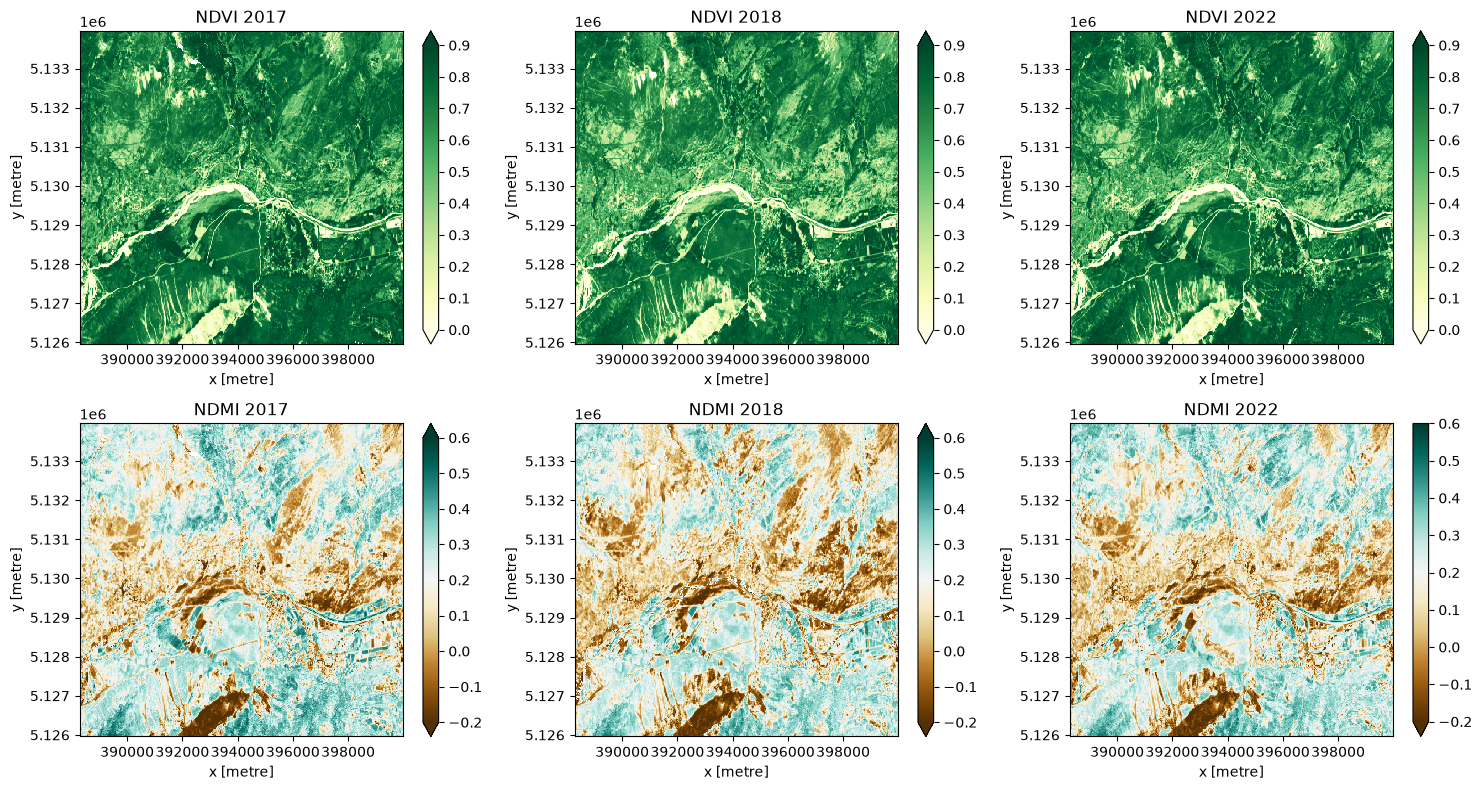

In [8]:
fig, axes = plt.subplots(2, len(indices), figsize=(5*len(indices), 8), squeeze=False)
for j, (y, d) in enumerate(indices.items()):
    d["ndvi"].plot(ax=axes[0,j], vmin=0, vmax=0.9, cmap="YlGn"); axes[0,j].set_title(f"NDVI {y}")
    d["ndmi"].plot(ax=axes[1,j], vmin=-0.2, vmax=0.6, cmap="BrBG"); axes[1,j].set_title(f"NDMI {y}")
plt.tight_layout()

## 3. Notes
- **What worked:** STAC search via Earth Search (AWS, no login) for Sentinel-2 L2A over the Pfynwald test bbox (summers 2017, 2018, 2022, cloud cover < 20 %). A summer median composite per year with SCL cloud/shadow/snow masking gave full-coverage NDVI and NDMI maps at 20 m for all three years. 2018 shows slightly lower NDMI (drier) than 2017, consistent with the drought.
- **What did not work:** Using only the least-cloudy single scene failed for 2017: the bbox lies at a Sentinel-2 tile border and the selected scene covered only a thin strip on the right edge. Fixed by compositing all scenes per summer (`groupby="solar_day"`, median over time).
- **Next decision:** (1) Add a forest mask (swissTLM3D / vegetation height model), since NDMI patterns are dominated by terrain and non-forest land. (2) Compute difference maps (2018 − 2017, 2022 − 2017) for NDVI and NDMI. (3) Check whether reference damage data (Canton Valais / WSL) is available for evaluation; otherwise validate visually with swissIMAGE.